<a href="https://colab.research.google.com/github/Yugshri/CV1/blob/main/CV1ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [99]:
# Force-install the latest stable versions
!pip install --upgrade deepface
!pip install tf-keras opencv-python-headless

In [100]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode

def take_photo(filename='photo.jpg', quality=0.8):
  js = Javascript('''
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const capture = document.createElement('button');
      capture.textContent = 'Capture Expression';
      div.appendChild(capture);

      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});

      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();

      // Wait for Capture to be clicked.
      await new Promise((resolve) => capture.onclick = resolve);

      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }
    ''')
  display(js)
  data = eval_js('takePhoto({})'.format(quality))
  binary = b64decode(data.split(',')[1])
  with open(filename, 'wb') as f:
    f.write(binary)
  return filename

In [101]:
mood_library = {
    "happy": {
        "vibe": "High Energy & Positivity",
        "genres": ["Uptempo Punjabi", "Nu-Disco"],
        "video_id": "CnBX7_ErLvA",
        "song_name": "Summer High - AP Dhillon"
    },
    "sad": {
        "vibe": "Low Energy & Reflective",
        "genres": ["Ghazals", "Lofi"],
        "video_id": "uhx3rokXL8g",
        "song_name": "Gul - Anuv Jain"
    },
    "angry": {
        "vibe": "High Intensity & Aggressive",
        "genres": ["Hardcore Rock", "Phonk"],
        "video_id": "z-YspVGcs38",
        "song_name": "295 - Sidhu Moose Wala"
    },
    "neutral": {
        "vibe": "Balanced & Calm",
        "genres": ["Deep House", "Jazz"],
        "video_id": "_kUrW9SEaJc",
        "song_name": "Sage - Ritviz"
    },
    "surprise": {
        "vibe": "Spontaneous & Energetic",
        "genres": ["Hyperpop", "Experimental"],
        "video_id": "cl0a3i2wFcc",
        "song_name": "G.O.A.T - Diljit Dosanjh"
    }
}

In [102]:
# --- STEP 1: THE XAI ENGINE (Grad-CAM) ---
import tensorflow as tf
import numpy as np

def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    # 1. Create a model that maps the input image to the activations
    # of the last conv layer as well as the output predictions
    grad_model = tf.keras.models.Model(
        [model.inputs], [model.get_layer(last_conv_layer_name).output, model.output]
    )

    # 2. Compute the gradient of the top predicted class for our input image
    with tf.GradientTape() as tape:
        last_conv_layer_output, preds = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]

    # 3. This is the gradient of the output neuron with regard to the output feature map
    grads = tape.gradient(class_channel, last_conv_layer_output)

    # 4. Mean intensity of the gradient over a specific feature map channel
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    # 5. Multiply each channel in the feature map array by "how important this channel is"
    last_conv_layer_output = last_conv_layer_output[0]
    heatmap = last_conv_layer_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    # 6. Normalize the heatmap between 0 & 1 for visualization
    heatmap = tf.maximum(heatmap, 0) / tf.reduce_max(heatmap)
    return heatmap.numpy()

In [103]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode

def take_photo_auto(filename='photo.jpg', quality=0.8):
  js = Javascript('''
    async function takePhotoAuto(quality) {
      const div = document.createElement('div');
      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});
      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();

      // Wait 2 seconds then capture
      await new Promise((resolve) => setTimeout(resolve, 2000));

      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }
    ''')
  display(js)
  data = eval_js('takePhotoAuto({})'.format(quality))
  binary = b64decode(data.split(',')[1])
  with open(filename, 'wb') as f:
    f.write(binary)
  return filename

📸 Initializing... Look at the camera!


<IPython.core.display.Javascript object>

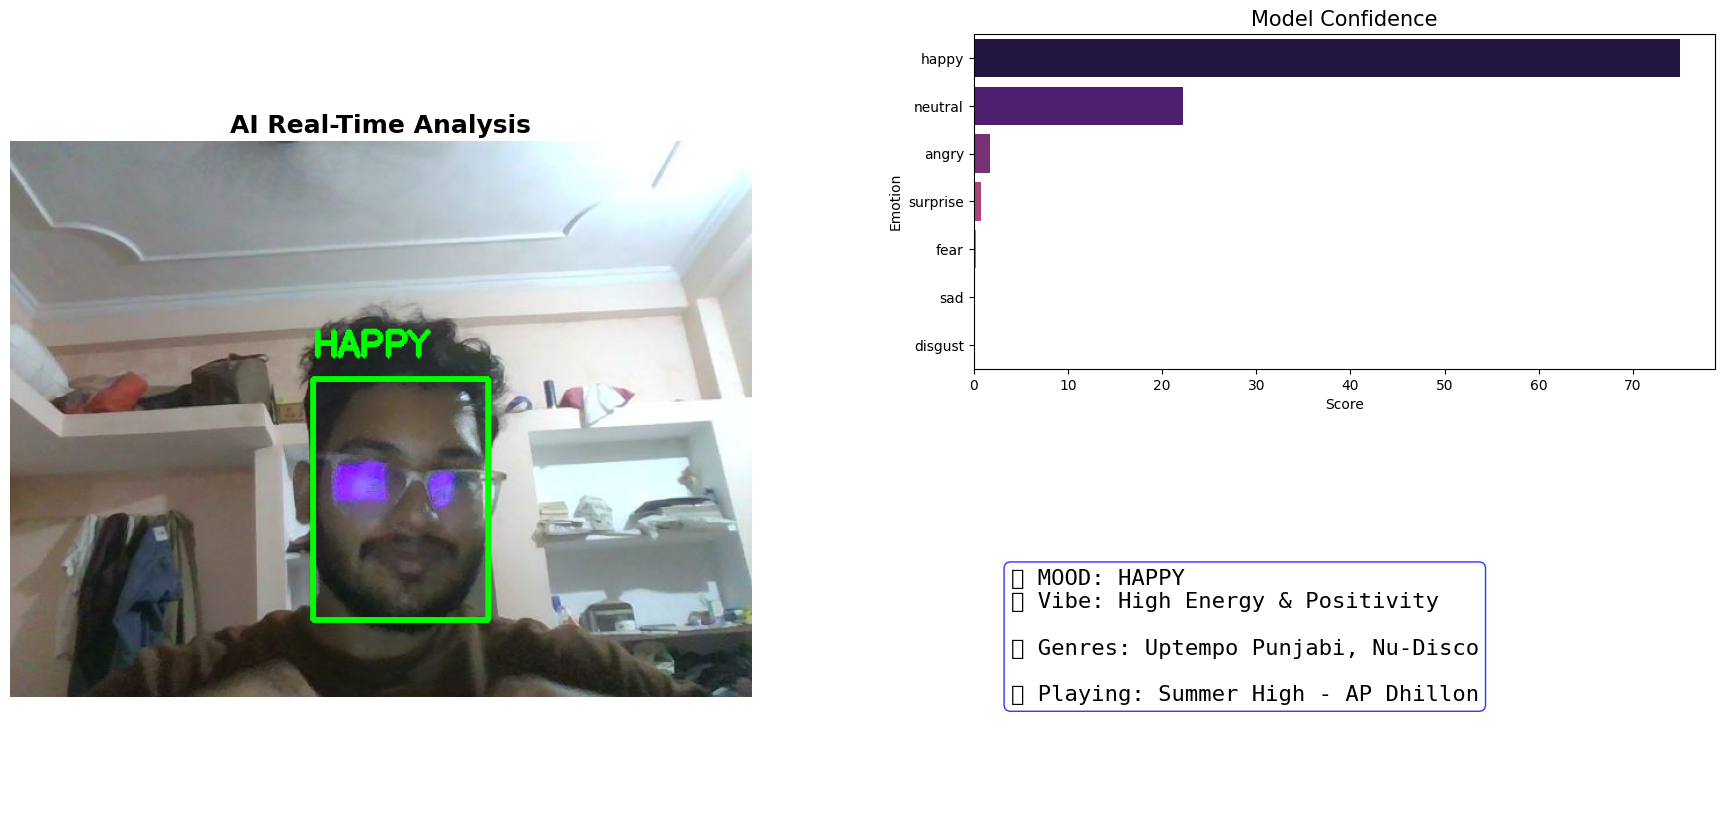


📺 Vibe Check: Playing Summer High - AP Dhillon for you!


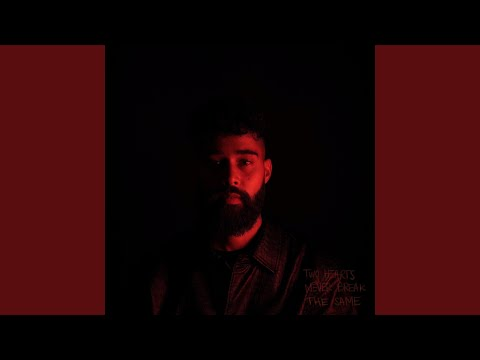

In [104]:
import cv2
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from deepface import DeepFace
from IPython.display import YouTubeVideo, display

try:
    # 1. Capture the photo automatically
    print("📸 Initializing... Look at the camera!")
    filename = take_photo_auto()

    # 2. Stable Emotion Analysis
    # We use RetinaFace as the backend for the best detection
    results = DeepFace.analyze(img_path=filename, actions=['emotion'],
                               detector_backend='retinaface', enforce_detection=False)

    img = cv2.imread(filename)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # 3. Setup Dashboard Layout
    fig = plt.figure(figsize=(22, 10))
    grid = plt.GridSpec(2, 2, wspace=0.3, hspace=0.3)
    ax_vision = fig.add_subplot(grid[:, 0])
    ax_chart = fig.add_subplot(grid[0, 1])
    ax_rec = fig.add_subplot(grid[1, 1])

    # 4. Draw labels for detected faces
    for face in results:
        x, y, w, h = face['region']['x'], face['region']['y'], face['region']['w'], face['region']['h']
        emotion = face['dominant_emotion']
        cv2.rectangle(img_rgb, (x, y), (x + w, y + h), (0, 255, 0), 4)
        cv2.putText(img_rgb, emotion.upper(), (x, y - 20), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 3)

    ax_vision.imshow(img_rgb)
    ax_vision.axis('off')
    ax_vision.set_title("AI Real-Time Analysis", fontsize=18, fontweight='bold')

    # 5. Emotion Probability Chart
    emotion_data = results[0]['emotion']
    emotion_df = pd.DataFrame(emotion_data.items(), columns=['Emotion', 'Score']).sort_values(by='Score', ascending=False)
    sns.barplot(x='Score', y='Emotion', data=emotion_df, ax=ax_chart, palette='magma')
    ax_chart.set_title("Model Confidence", fontsize=15)

    # 6. Music Recommendation Card
    best_mood = results[0]['dominant_emotion']
    if best_mood in mood_library:
        rec = mood_library[best_mood]
        ax_rec.axis('off')
        card_text = (f"🎵 MOOD: {best_mood.upper()}\n✨ Vibe: {rec['vibe']}\n\n"
                     f"🎧 Genres: {', '.join(rec['genres'])}\n\n"
                     f"💿 Playing: {rec['song_name']}")
        ax_rec.text(0.05, 0.5, card_text, fontsize=16, va='center', family='monospace',
                    bbox=dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='blue'))

        plt.show()

        # 7. Embed the Video
        print(f"\n📺 Vibe Check: Playing {rec['song_name']} for you!")
        display(YouTubeVideo(rec['video_id'], width=800, height=450, autoplay=1))

except Exception as err:
    print(f"Error logic: {err}")